<a href="https://colab.research.google.com/github/Rubal-code/DEEP-LEARNING/blob/main/01_pytorch_fundamentals_video8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
what_were_covering = {
    1:"data (prepare and load)",
    2:"build model",
    3:"fitting the model to data (training)",
    4:"making predictions and evaluating the model (inference)",
    5:"saving and loading a trained model",
    6:"putting it all together"
}
what_were_covering

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating the model (inference)',
 5: 'saving and loading a trained model',
 6: 'putting it all together'}

In [2]:
import torch
from torch import nn # nn contains the all pytorch's building blocks for making the neural network
import matplotlib.pyplot as plt

torch.__version__

'2.14.1+cpu'

In [3]:
# create known parameters
weight = 0.7
bias = 0.3
# create
start = 0
end = 1
step = 0.02
X=torch.arange(start=start,end=end,step=step).unsqueeze(dim=1)
y=weight*X+bias
X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(X), len(y)

(50, 50)

### spliting the data into training and testing data


In [5]:
train_split=int(0.7 * len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

In [6]:
len(X_train),len(y_train),len(X_test),len(y_test)

(35, 35, 15, 15)

In [7]:
def plot_predictions(
                    train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None
                    ):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c="b",s=4,label="training data")
  plt.scatter(test_data,test_labels,c="g",s=4,label="testing data")
  if predictions is not None:
    plt.scatter(test_data,predictions,c="r",s=4,label="predictions")


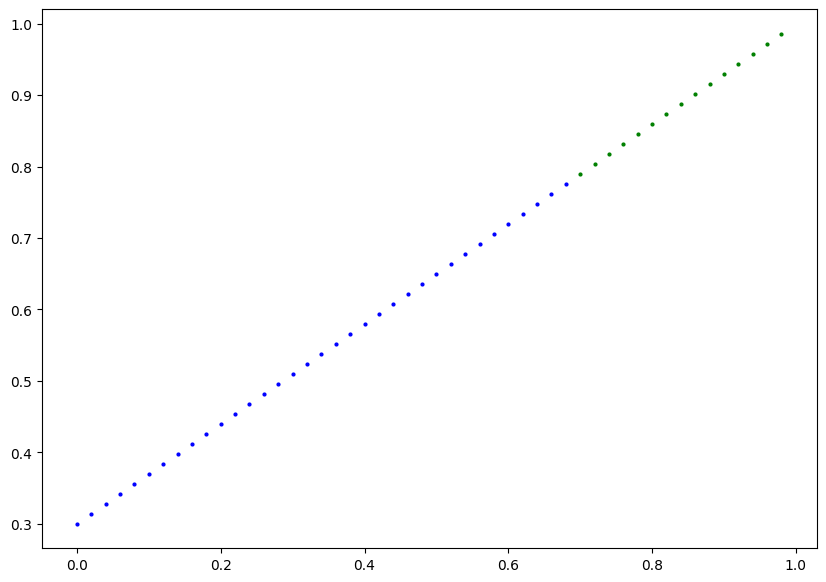

In [8]:
plot_predictions()

In [9]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(
        1,
        requires_grad=True,
        dtype=torch.float
    ))
    self.bias = nn.Parameter(torch.randn(
        1,
        requires_grad=True,
        dtype=torch.float
    ))
  # forward method to define the computation in the model
  def forward(self,x:torch.Tensor)->torch.Tensor:
    return self.weights * x + self.bias


In [10]:
lr=LinearRegressionModel()
lr.state_dict()

OrderedDict([('weights', tensor([2.0481])), ('bias', tensor([1.5812]))])

### pytorch model building essentials

* torch.nn - contains all the buildings for computational graph (a neural network is considered as computational graph)
* torch.nn.Parameter - what parameters should our model try and learn, often a pytorch layer from torch.nn will set for us
* torch.nn.Module - the base class for all neural networks modules , if you subclass it, you should overwrite the forward()
* torch.optim - this is where optimizersin pytorch live , they will help with the gradient descent
* forward() - this method defines what happpens in forward computation
* Dataset – Stores and accesses your data.
* DataLoader – Loads data in batches and makes it easier to train models.

In [11]:
torch.manual_seed(42)
# create an instance of the model
model_0 = LinearRegressionModel()

list(model_0.parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [12]:
# list named parameters
model_0.state_dict()      # i want to get closer to the weigth and bias which i have already intialized

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

# lets calculate the predictions using `torch.inference_mode()`
*To check our models predictive power , lets see how well it predicts `y_test` on based on `x_test`
* when we pass the data it will gone throught the forward pass


In [13]:
# make the predictions with model
with torch.inference_mode():
  y_pred = model_0(X_test)
y_pred
# you can also do it with like this torch.no_grad(), however the torch.inference_mode ()is prefered we do this things beacuse it makes the prediction faster and it discards the gradients and usefull things during the training phasee which we had use
# with torch.no_grad():
  #y_pred = model_0(y_test)
# y_pred


tensor([[0.3645],
        [0.3712],
        [0.3780],
        [0.3847],
        [0.3914],
        [0.3982],
        [0.4049],
        [0.4116],
        [0.4184],
        [0.4251],
        [0.4318],
        [0.4386],
        [0.4453],
        [0.4520],
        [0.4588]])

In [14]:
y_test

tensor([[0.7900],
        [0.8040],
        [0.8180],
        [0.8320],
        [0.8460],
        [0.8600],
        [0.8740],
        [0.8880],
        [0.9020],
        [0.9160],
        [0.9300],
        [0.9440],
        [0.9580],
        [0.9720],
        [0.9860]])

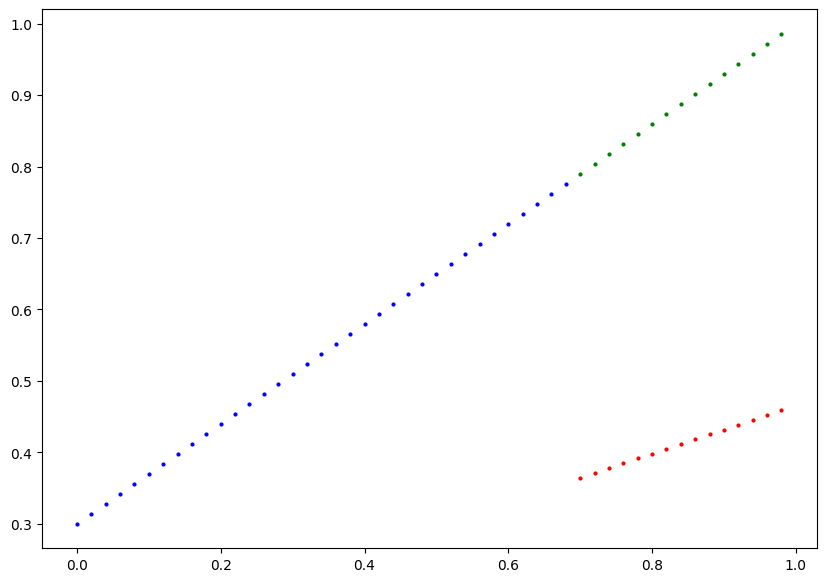

In [15]:
plot_predictions(predictions = y_pred)

# train the model
the whole idea of the training for the model to move from some unknown parameters to some known parameters

or in other words from poor repressentation od data to better representation

one way to measure how poor or how wrong your models predictions are is to use the loss function
* **loss function**- a function is to measure how wrong your models prediction are to ideal outputs , lower is better
* **optimizer** - takes into account the loss of a model and adjusts the model's parameters(eg - weight and bias)
   
          inside the optimizer we have to set the two parameters:
          1) `params`-the model parameters you would like to optimize , for example `params = model_0.parameters()`
          2)lr(learning rate) - the learing rate is a hyperparameter that defineshow big and small optimizer changes the parameter with each step (the small lr results in small change and large lr with large change)

In [16]:
# setup loss function
loss_fn = nn.L1Loss() # nn.BCELoss for the classification problem

# setup an optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(),lr=0.01)


PyTorch models learn by comparing predictions to ground truth labels, computing loss, and adjusting parameters via backpropagation and gradient descent.

# PyTorch Training Loop Core Steps
Loop through data: Iterate across epochs and batches.

Forward pass: Compute predictions through the model (model(x)).

Calculate loss: Compare predictions to target labels using a loss function.

Optimizer zero grad: Clear accumulated gradients before backpropagation (optimizer.zero_grad()).

Loss backward: Compute gradients through backpropagation (loss.backward()).

Optimizer step: Update model parameters (optimizer.step()).

In [22]:
torch.manual_seed(42)
# An epoch is the one loop through the data
epoch = 100
##### training ######
# 0. loop through the data
for epoch in range(epoch):
  # set the model to training mode
  model_0.train() # train the model in pytorch sets all the parameters that require the gradients to require the gradients
  # 1. forward pass
  y_pred = model_0(X_train)
  #2 calculate loss
  loss = loss_fn(y_pred,y_train)
  # print(f"Loss{loss}")
  #3 optimizer zero grad
  optimizer.zero_grad()
  #4 loss backward
  loss.backward()
  #5 optimizer step
  optimizer.step()# by default how the optimizer changes will accumualte through loop so .. we have to zero them above in the step 3 for the next iteration of the loop
  ##### testing ######$
  model_0.eval()#turns off the gradient tracking
  with torch.inference_mode():
    test_pred=model_0(X_test)
    test_loss=loss_fn(test_pred,y_test)
  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss} | Test Loss: {test_loss}")

Epoch: 0 | Loss: 0.026395238935947418 | Test Loss: 0.07136490941047668
Epoch: 10 | Loss: 0.023672932758927345 | Test Loss: 0.06407131999731064
Epoch: 20 | Loss: 0.020944364368915558 | Test Loss: 0.05677773430943489
Epoch: 30 | Loss: 0.018215805292129517 | Test Loss: 0.048739925026893616
Epoch: 40 | Loss: 0.01549520157277584 | Test Loss: 0.04144632816314697
Epoch: 50 | Loss: 0.012774603441357613 | Test Loss: 0.034152738749980927
Epoch: 60 | Loss: 0.010049331933259964 | Test Loss: 0.02685915306210518
Epoch: 70 | Loss: 0.007320757489651442 | Test Loss: 0.019565558061003685
Epoch: 80 | Loss: 0.004595165606588125 | Test Loss: 0.011527741327881813
Epoch: 90 | Loss: 0.0018745660781860352 | Test Loss: 0.004234150983393192


In [18]:
model_0.state_dict()

OrderedDict([('weights', tensor([0.5495])), ('bias', tensor([0.3540]))])

In [19]:
weight,bias

(0.7, 0.3)

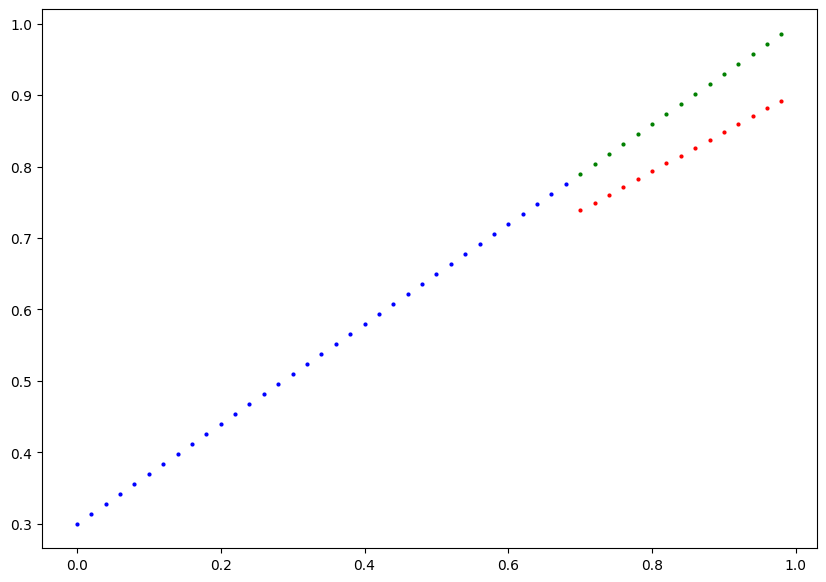

In [20]:
with torch.inference_mode():
  y_pred_new = model_0(X_test)
plot_predictions(predictions=y_pred_new)